In [1]:
from pathlib import Path
from collections import Counter

import cv2
import matplotlib.pyplot as plt

# Racine du projet
PROJECT_ROOT = Path.cwd().parent

# Dataset original
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "NEU-DET"
IMAGE_DIR = DATA_DIR / "IMAGES"
ANNOTATION_DIR = DATA_DIR / "ANNOTATIONS"

# Dataset préparé
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "detection"

print("Projet :", PROJECT_ROOT)
print("Images originales :", IMAGE_DIR)
print("Annotations :", ANNOTATION_DIR)
print("Dataset préparé :", PROCESSED_DIR)

Projet : c:\Users\yassmine\Downloads\industrial-defect-detection
Images originales : c:\Users\yassmine\Downloads\industrial-defect-detection\data\raw\NEU-DET\IMAGES
Annotations : c:\Users\yassmine\Downloads\industrial-defect-detection\data\raw\NEU-DET\ANNOTATIONS
Dataset préparé : c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection


In [2]:
CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

CLASS_TO_ID = {
    class_name: class_id
    for class_id, class_name in enumerate(CLASS_NAMES)
}

print(CLASS_TO_ID)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [3]:
from sklearn.model_selection import train_test_split

images = sorted(IMAGE_DIR.glob("*.jpg"))

image_classes = [
    image_path.stem.rsplit("_", 1)[0]
    for image_path in images
]

train_images, temp_images, train_classes, temp_classes = train_test_split(
    images,
    image_classes,
    test_size=0.30,
    random_state=42,
    stratify=image_classes
)

val_images, test_images = train_test_split(
    temp_images,
    test_size=0.50,
    random_state=42,
    stratify=temp_classes
)

print("Train :", len(train_images))
print("Val   :", len(val_images))
print("Test  :", len(test_images))

Train : 1260
Val   : 270
Test  : 270


In [4]:
import xml.etree.ElementTree as ET


def create_multilabel(xml_path):
    """
    Transforme les classes présentes dans un XML
    en vecteur multi-label de longueur 6.
    """

    tree = ET.parse(xml_path)
    root = tree.getroot()

    labels = [0] * len(CLASS_NAMES)

    for obj in root.findall("object"):
        class_name = obj.find("name").text

        class_id = CLASS_TO_ID[class_name]

        labels[class_id] = 1

    return labels

In [5]:
test_xml = ANNOTATION_DIR / "crazing_1.xml"

label = create_multilabel(test_xml)

print("XML :", test_xml.name)
print("Label :", label)

XML : crazing_1.xml
Label : [1, 0, 0, 0, 0, 0]


In [8]:
def read_annotation(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    objects = []

    for obj in root.findall("object"):
        class_name = obj.find("name").text
        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        objects.append({
            "class": class_name,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        })

    return objects

In [9]:
multi_class_xml = next(
    xml_path
    for xml_path in ANNOTATION_DIR.glob("*.xml")
    if len({
        obj["class"]
        for obj in read_annotation(xml_path)
    }) > 1
)

label = create_multilabel(multi_class_xml)

print("XML :", multi_class_xml.name)
print("Classes présentes :")

for class_name, value in zip(CLASS_NAMES, label):
    if value == 1:
        print(" -", class_name)

print("Vecteur :", label)

XML : crazing_104.xml
Classes présentes :
 - crazing
 - patches
Vecteur : [1, 0, 1, 0, 0, 0]


In [10]:
def build_classification_dataset(image_paths):
    dataset = []

    for image_path in image_paths:
        xml_path = ANNOTATION_DIR / f"{image_path.stem}.xml"

        labels = create_multilabel(xml_path)

        dataset.append({
            "image_path": image_path,
            "labels": labels
        })

    return dataset

In [11]:
train_data = build_classification_dataset(train_images)
val_data = build_classification_dataset(val_images)
test_data = build_classification_dataset(test_images)

print("Train :", len(train_data))
print("Validation :", len(val_data))
print("Test :", len(test_data))

Train : 1260
Validation : 270
Test : 270


In [12]:
sample = train_data[0]

print("Image :", sample["image_path"].name)
print("Labels :", sample["labels"])

print("Classes présentes :")
for class_name, value in zip(CLASS_NAMES, sample["labels"]):
    if value == 1:
        print(" -", class_name)

Image : scratches_111.jpg
Labels : [0, 1, 0, 0, 0, 1]
Classes présentes :
 - inclusion
 - scratches


In [13]:
def count_labels(dataset):
    counts = Counter()

    for sample in dataset:
        for class_name, value in zip(CLASS_NAMES, sample["labels"]):
            if value == 1:
                counts[class_name] += 1

    return counts

In [14]:
train_label_counts = count_labels(train_data)
val_label_counts = count_labels(val_data)
test_label_counts = count_labels(test_data)

print("Répartition des labels - Train")
for class_name in CLASS_NAMES:
    print(f"{class_name:20s} : {train_label_counts[class_name]}")

print("\nRépartition des labels - Validation")
for class_name in CLASS_NAMES:
    print(f"{class_name:20s} : {val_label_counts[class_name]}")

print("\nRépartition des labels - Test")
for class_name in CLASS_NAMES:
    print(f"{class_name:20s} : {test_label_counts[class_name]}")

Répartition des labels - Train
crazing              : 210
inclusion            : 270
patches              : 241
pitted_surface       : 211
rolled-in_scale      : 210
scratches            : 210

Répartition des labels - Validation
crazing              : 45
inclusion            : 56
patches              : 48
pitted_surface       : 45
rolled-in_scale      : 45
scratches            : 45

Répartition des labels - Test
crazing              : 45
inclusion            : 56
patches              : 53
pitted_surface       : 45
rolled-in_scale      : 45
scratches            : 45


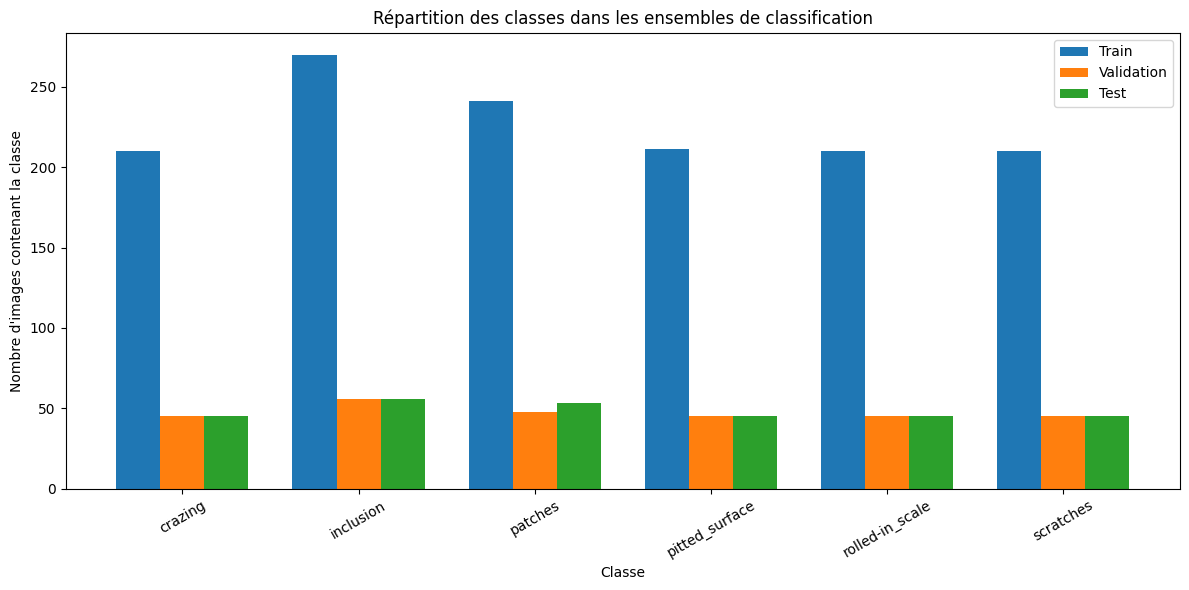

In [15]:
import numpy as np

x = np.arange(len(CLASS_NAMES))
width = 0.25

train_values = [train_label_counts[name] for name in CLASS_NAMES]
val_values = [val_label_counts[name] for name in CLASS_NAMES]
test_values = [test_label_counts[name] for name in CLASS_NAMES]

plt.figure(figsize=(12, 6))

plt.bar(x - width, train_values, width, label="Train")
plt.bar(x, val_values, width, label="Validation")
plt.bar(x + width, test_values, width, label="Test")

plt.xticks(x, CLASS_NAMES, rotation=30)
plt.xlabel("Classe")
plt.ylabel("Nombre d'images contenant la classe")
plt.title("Répartition des classes dans les ensembles de classification")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
%pip install torch torchvision

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 1.3/124.1 MB 8.6 MB/s eta 0:00:15
   - -------------------------------------- 3.9/124.1 MB 10.7 MB/s eta 0:00:12
   -- ------------------------------------- 6.3/124.1 MB 11.3 MB/s eta 0:00:11
   -- ------------------------------------- 8.7/124.1 MB 11.0 MB/s eta 0:00:11
   --- ------------------------------------ 10.7/124.1 MB 11.2 MB/s eta 0:00:11
   ---- ----------------------------------- 13.1/124.1 MB 11.2 MB/s eta 0:00:10
   ----- ---------------------------------- 15.7/124.1 MB 11.4 MB/s eta 0:00:10
   ----- ---------------------------------- 18.4/124.1 MB 11.5 MB/s eta 0:00:10
   ------ --------------------------------- 20.4/124.1 MB 11.2 MB/s eta 0:00:10
   ------- -------------------------------- 22.5/124.1 MB 11.1 MB/s eta 0:00:10
   -------- ------------------------------- 25.2/124.1 MB 11.2 MB/s eta 0:00:09
   -------- ------------------------------- 27.5/124.1


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import torch
import torchvision

print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("CUDA disponible :", torch.cuda.is_available())

PyTorch : 2.14.1+cpu
Torchvision : 0.29.1+cpu
CUDA disponible : False


In [19]:
from torchvision import transforms

IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [23]:
import torch

In [24]:
from torch.utils.data import Dataset
from PIL import Image


class SteelDefectDataset(Dataset):

    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample = self.data[index]

        image_path = sample["image_path"]
        labels = sample["labels"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        labels = torch.tensor(labels, dtype=torch.float32)

        return image, labels

In [25]:
train_dataset = SteelDefectDataset(
    train_data,
    transform=train_transform
)

val_dataset = SteelDefectDataset(
    val_data,
    transform=val_test_transform
)

test_dataset = SteelDefectDataset(
    test_data,
    transform=val_test_transform
)

print("Train :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

Train : 1260
Validation : 270
Test : 270


In [26]:
image, labels = train_dataset[0]

print("Taille de l'image :", image.shape)
print("Labels :", labels)

Taille de l'image : torch.Size([3, 224, 224])
Labels : tensor([0., 1., 0., 0., 0., 1.])


In [27]:
import torch
import torch.nn as nn
from torchvision import models

model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\yassmine/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.6MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [28]:
print(model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [29]:
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    len(CLASS_NAMES)
)

print(model.fc)

Linear(in_features=512, out_features=6, bias=True)


In [30]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device utilisé :", device)

Device utilisé : cpu


In [31]:
model = model.to(device)

print("Modèle chargé sur :", device)

Modèle chargé sur : cpu


In [32]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train batches :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches : 40
Validation batches : 9
Test batches : 9


In [33]:
images, labels = next(iter(train_loader))

print("Images :", images.shape)
print("Labels :", labels.shape)

Images : torch.Size([32, 3, 224, 224])
Labels : torch.Size([32, 6])


In [34]:
criterion = nn.BCEWithLogitsLoss()

In [35]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [36]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Images :", images.shape)
print("Labels :", labels.shape)
print("Outputs :", outputs.shape)

Images : torch.Size([32, 3, 224, 224])
Labels : torch.Size([32, 6])
Outputs : torch.Size([32, 6])


In [37]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [39]:
def evaluate_model(model, data_loader, criterion, device, threshold=0.5):
    model.eval()

    total_loss = 0.0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= threshold).float()

            all_predictions.append(
                predictions.cpu()
            )

            all_labels.append(
                labels.cpu()
            )

    all_predictions = torch.cat(all_predictions).numpy()
    all_labels = torch.cat(all_labels).numpy()

    average_loss = total_loss / len(data_loader)

    precision = precision_score(
        all_labels,
        all_predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="micro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="micro",
        zero_division=0
    )

    return average_loss, precision, recall, f1

In [40]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):

    model.train()

    total_loss = 0.0

    for images, labels in data_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(data_loader)

    return average_loss

In [41]:
NUM_EPOCHS = 10

best_f1 = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

MODEL_DIR = PROJECT_ROOT / "models" / "classification"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "resnet18_best.pth"

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_precision, val_recall, val_f1 = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print(
            f"  ✓ Meilleur modèle sauvegardé "
            f"(F1 = {best_f1:.4f})"
        )

Epoch [1/10] | Train Loss: 0.2608 | Val Loss: 0.0910 | Precision: 0.9259 | Recall: 0.9683 | F1: 0.9466
  ✓ Meilleur modèle sauvegardé (F1 = 0.9466)
Epoch [2/10] | Train Loss: 0.0739 | Val Loss: 0.0547 | Precision: 0.9718 | Recall: 0.9718 | F1: 0.9718
  ✓ Meilleur modèle sauvegardé (F1 = 0.9718)
Epoch [3/10] | Train Loss: 0.0502 | Val Loss: 0.0333 | Precision: 0.9893 | Recall: 0.9789 | F1: 0.9841
  ✓ Meilleur modèle sauvegardé (F1 = 0.9841)
Epoch [4/10] | Train Loss: 0.0411 | Val Loss: 0.0257 | Precision: 0.9858 | Recall: 0.9789 | F1: 0.9823
Epoch [5/10] | Train Loss: 0.0341 | Val Loss: 0.0226 | Precision: 0.9894 | Recall: 0.9824 | F1: 0.9859
  ✓ Meilleur modèle sauvegardé (F1 = 0.9859)
Epoch [6/10] | Train Loss: 0.0303 | Val Loss: 0.0206 | Precision: 0.9894 | Recall: 0.9824 | F1: 0.9859
Epoch [7/10] | Train Loss: 0.0248 | Val Loss: 0.0243 | Precision: 0.9691 | Recall: 0.9930 | F1: 0.9809
Epoch [8/10] | Train Loss: 0.0230 | Val Loss: 0.0202 | Precision: 0.9929 | Recall: 0.9824 | F1: 0.9

In [42]:
best_model = models.resnet18(
    weights=None
)

num_features = best_model.fc.in_features

best_model.fc = nn.Linear(
    num_features,
    len(CLASS_NAMES)
)

best_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

best_model = best_model.to(device)

print("Meilleur modèle chargé.")

Meilleur modèle chargé.


In [43]:
test_loss, test_precision, test_recall, test_f1 = evaluate_model(
    best_model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss      : {test_loss:.4f}")
print(f"Test Precision  : {test_precision:.4f}")
print(f"Test Recall     : {test_recall:.4f}")
print(f"Test F1         : {test_f1:.4f}")

Test Loss      : 0.0356
Test Precision  : 0.9754
Test Recall     : 0.9619
Test F1         : 0.9686


In [44]:
from sklearn.metrics import precision_recall_fscore_support

def evaluate_per_class(model, data_loader, device, threshold=0.5):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= threshold).float()

            all_predictions.append(
                predictions.cpu()
            )

            all_labels.append(
                labels
            )

    all_predictions = torch.cat(all_predictions).numpy()
    all_labels = torch.cat(all_labels).numpy()

    precision, recall, f1, support = precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average=None,
        zero_division=0
    )

    return precision, recall, f1, support

In [45]:
precision, recall, f1, support = evaluate_per_class(
    best_model,
    test_loader,
    device
)

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:20s} | "
        f"Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | "
        f"F1: {f1[i]:.4f} | "
        f"Support: {support[i]}"
    )

crazing              | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | Support: 45
inclusion            | Precision: 0.9057 | Recall: 0.8571 | F1: 0.8807 | Support: 56
patches              | Precision: 0.9615 | Recall: 0.9434 | F1: 0.9524 | Support: 53
pitted_surface       | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | Support: 45
rolled-in_scale      | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | Support: 45
scratches            | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | Support: 45


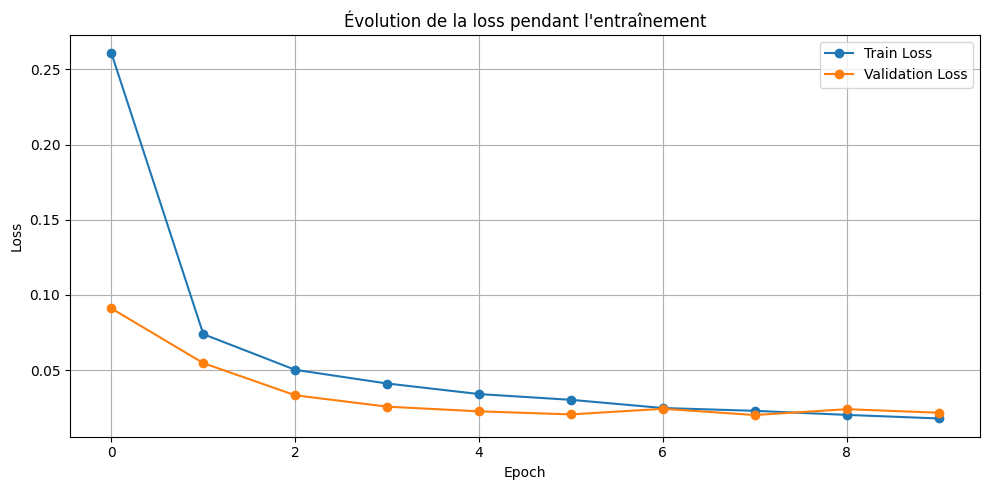

In [46]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Évolution de la loss pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

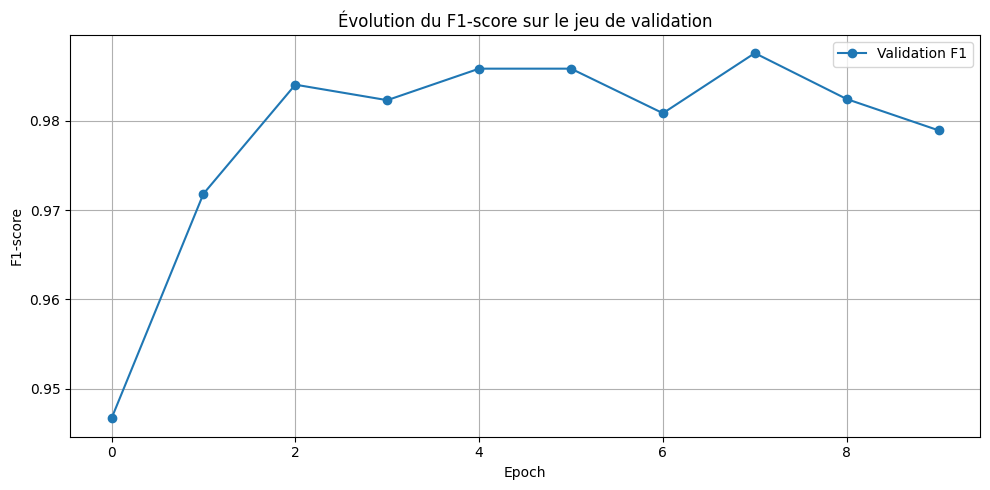

In [47]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.title("Évolution du F1-score sur le jeu de validation")
plt.xlabel("Epoch")
plt.ylabel("F1-score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

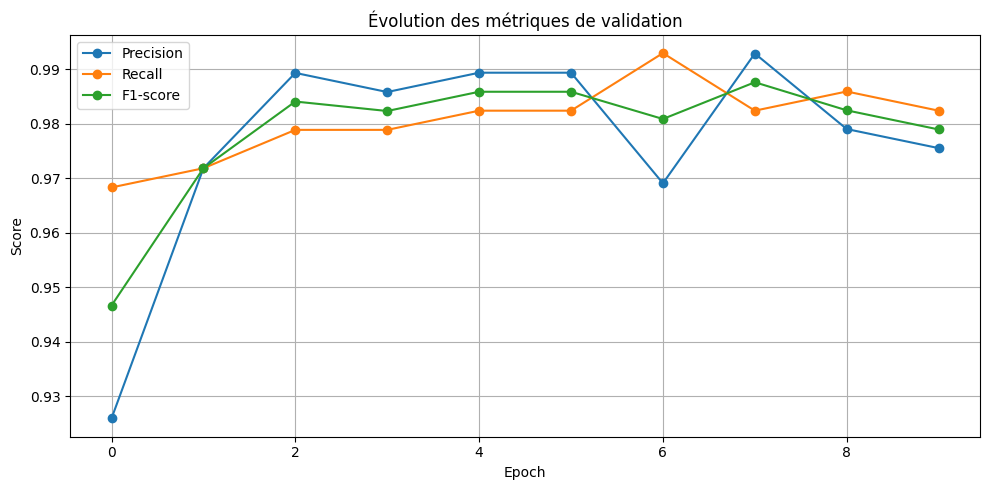

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["val_precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    history["val_recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    history["val_f1"],
    marker="o",
    label="F1-score"
)

plt.title("Évolution des métriques de validation")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [49]:
import numpy as np

def get_predictions(model, data_loader, device, threshold=0.5):

    model.eval()

    all_probabilities = []
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= threshold).float()

            all_probabilities.append(
                probabilities.cpu()
            )

            all_predictions.append(
                predictions.cpu()
            )

            all_labels.append(
                labels
            )

    probabilities = torch.cat(all_probabilities).numpy()
    predictions = torch.cat(all_predictions).numpy()
    labels = torch.cat(all_labels).numpy()

    return probabilities, predictions, labels

In [50]:
probabilities, predictions, labels = get_predictions(
    best_model,
    test_loader,
    device
)

print("Probabilités :", probabilities.shape)
print("Prédictions  :", predictions.shape)
print("Labels réels :", labels.shape)

Probabilités : (270, 6)
Prédictions  : (270, 6)
Labels réels : (270, 6)


In [51]:
error_indices = []

for i in range(len(labels)):

    if not np.array_equal(
        labels[i],
        predictions[i]
    ):
        error_indices.append(i)

print("Nombre d'images avec au moins une erreur :", len(error_indices))

Nombre d'images avec au moins une erreur : 18


In [52]:
from PIL import Image

def show_errors(
    dataset,
    error_indices,
    probabilities,
    predictions,
    labels,
    class_names,
    max_images=12
):

    indices = error_indices[:max_images]

    cols = 3
    rows = int(np.ceil(len(indices) / cols))

    plt.figure(figsize=(15, 5 * rows))

    for position, index in enumerate(indices):

        image_path = dataset.data[index]["image_path"]

        image = Image.open(image_path).convert("RGB")

        real_classes = [
            class_names[j]
            for j, value in enumerate(labels[index])
            if value == 1
        ]

        predicted_classes = [
            class_names[j]
            for j, value in enumerate(predictions[index])
            if value == 1
        ]

        plt.subplot(rows, cols, position + 1)

        plt.imshow(image)

        plt.title(
            f"Réel : {', '.join(real_classes)}\n"
            f"Prédit : {', '.join(predicted_classes)}",
            fontsize=10
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

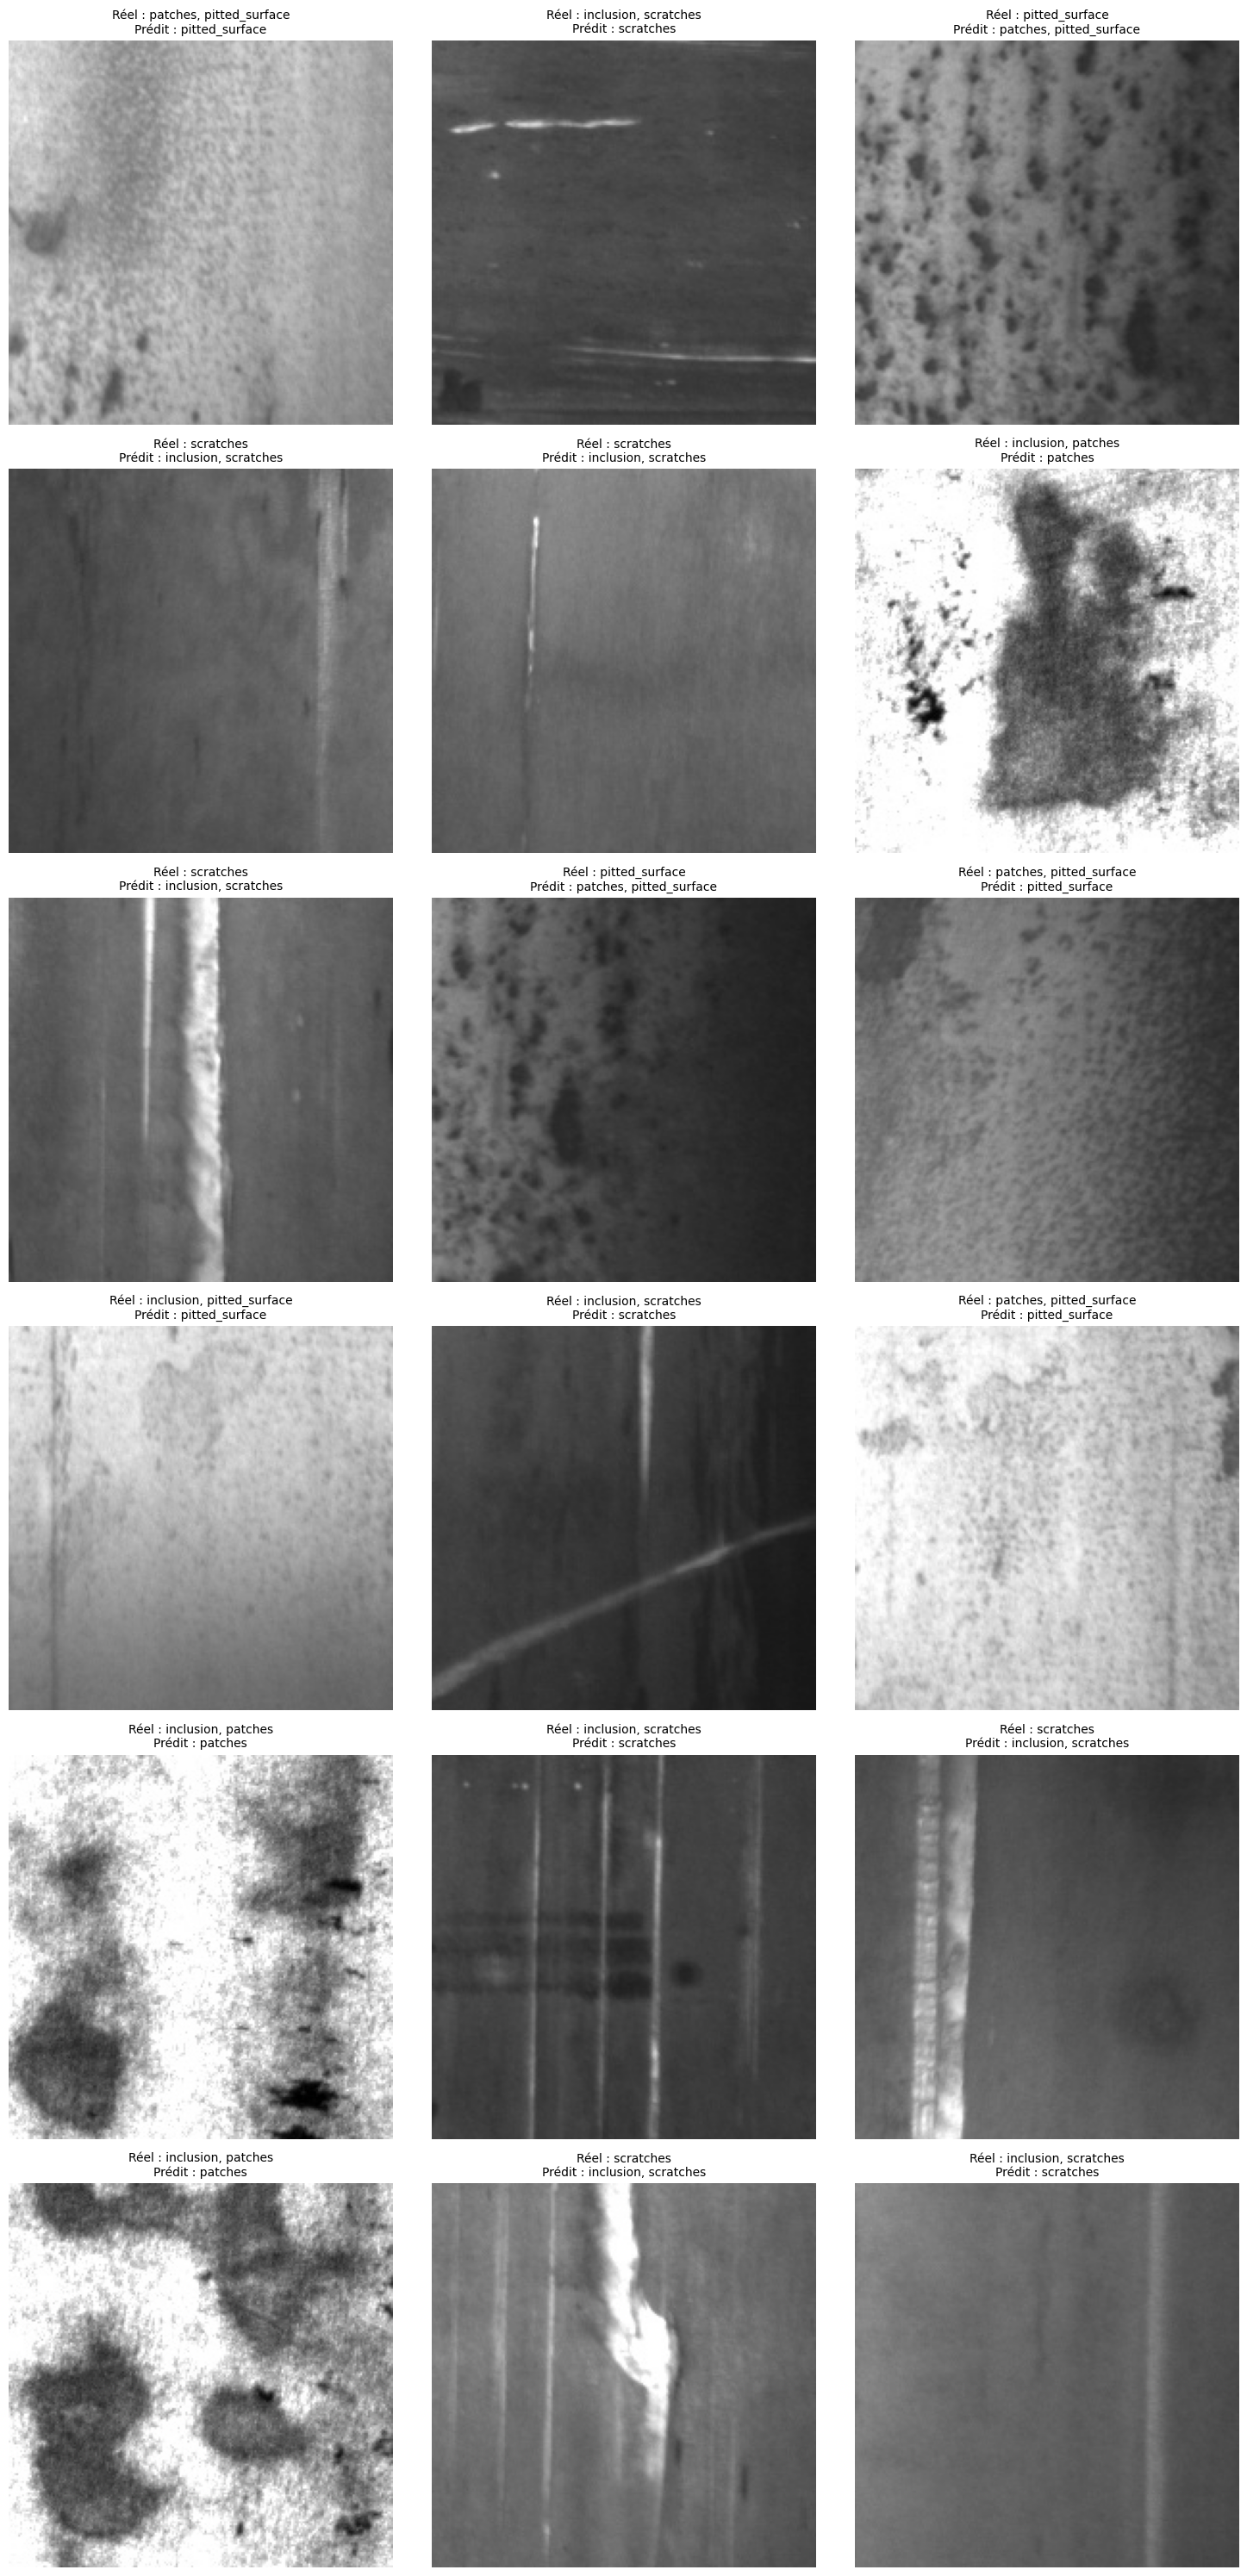

In [54]:
show_errors(
    test_dataset,
    error_indices,
    probabilities,
    predictions,
    labels,
    CLASS_NAMES,
    max_images=18
)

In [55]:
# Calcul des False Positives et False Negatives par classe

false_positives = []
false_negatives = []

for class_id, class_name in enumerate(CLASS_NAMES):

    fp = np.sum(
        (predictions[:, class_id] == 1) &
        (labels[:, class_id] == 0)
    )

    fn = np.sum(
        (predictions[:, class_id] == 0) &
        (labels[:, class_id] == 1)
    )

    false_positives.append(fp)
    false_negatives.append(fn)

    print(
        f"{class_name:20s} | "
        f"False Positives : {fp:2d} | "
        f"False Negatives : {fn:2d}"
    )

crazing              | False Positives :  0 | False Negatives :  0
inclusion            | False Positives :  5 | False Negatives :  8
patches              | False Positives :  2 | False Negatives :  3
pitted_surface       | False Positives :  0 | False Negatives :  0
rolled-in_scale      | False Positives :  0 | False Negatives :  0
scratches            | False Positives :  0 | False Negatives :  0


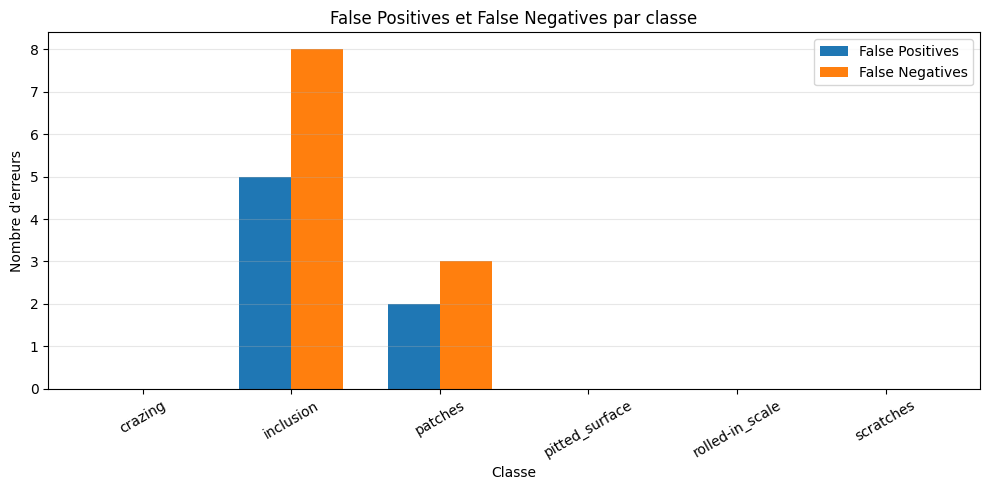

In [56]:
plt.figure(figsize=(10, 5))

x = np.arange(len(CLASS_NAMES))
width = 0.35

plt.bar(
    x - width / 2,
    false_positives,
    width,
    label="False Positives"
)

plt.bar(
    x + width / 2,
    false_negatives,
    width,
    label="False Negatives"
)

plt.xticks(
    x,
    CLASS_NAMES,
    rotation=30
)

plt.xlabel("Classe")
plt.ylabel("Nombre d'erreurs")
plt.title("False Positives et False Negatives par classe")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()